## Research Abstract Classifier

#### Load, Clean and Remove Duplicate

In [1]:
import pandas as pd

# 1. Load the three Scopus CSV files
df_sci = pd.read_csv("scopus_science.csv")
df_biz = pd.read_csv("scopus_business.csv")
df_soc = pd.read_csv("scopus_social.csv")

# 2. Keep only Title and Abstract, then add the label column
df_sci = df_sci[['Title', 'Abstract']]
df_sci['label'] = 'Science'

df_biz = df_biz[['Title', 'Abstract']]
df_biz['label'] = 'Business'

df_soc = df_soc[['Title', 'Abstract']]
df_soc['label'] = 'Social Science'

# 3. Combine all three into one dataframe
df = pd.concat([df_sci, df_biz, df_soc], ignore_index=True)

# Rename to lowercase column names
df = df.rename(columns={'Title': 'title', 'Abstract': 'abstract'})

print("Total raw rows loaded:", len(df))

# 4. Remove missing values (nulls)
df = df.dropna(subset=['title', 'abstract'])

# 5. Remove placeholder text and very short abstracts
df = df[df['abstract'] != '[No abstract available]']
df = df[df['abstract'].str.len() > 80]

# 6. Remove duplicate abstracts and duplicate titles
df = df.drop_duplicates(subset=['abstract'])
df = df.drop_duplicates(subset=['title'])

print("Total clean rows after Data Cleaning", len(df))
print("\nCounts per category:")
print(df['label'].value_counts())

Total raw rows loaded: 1200
Total clean rows after Data Cleaning 1198

Counts per category:
label
Science           400
Business          399
Social Science    399
Name: count, dtype: int64


#### Balance Classes

In [2]:
# 1. Find the smallest category size to balance equally
min_count = df['label'].value_counts().min()
print("Balancing each category to:", min_count)

# 2. Take the first 'min_count' rows from each category
df_sci_bal = df[df['label'] == 'Science'].head(min_count)
df_biz_bal = df[df['label'] == 'Business'].head(min_count)
df_soc_bal = df[df['label'] == 'Social Science'].head(min_count)

# 3. Combine them together
df_master = pd.concat([df_sci_bal, df_biz_bal, df_soc_bal], ignore_index=True)

# 4. Shuffle rows randomly
df_master = df_master.sample(frac=1.0, random_state=42).reset_index(drop=True)

# 5. Save final balanced file
df_master.to_csv("academic_abstracts_dataset.csv", index=False)

print("\n--- Final Master Dataset ---")
print("Total balanced rows:", len(df_master))
print(df_master['label'].value_counts())
df_master.head(3)

Balancing each category to: 399

--- Final Master Dataset ---
Total balanced rows: 1197
label
Social Science    399
Science           399
Business          399
Name: count, dtype: int64


,title,abstract,label
0,Conceptually demystifying the intersection bet...,The rise of generative artificial intelligence...,Social Science
1,Communication-efficient distributed inverse Qu...,The scalability of quantum computing is curren...,Science
2,Deep learning-driven de novo design of ribosom...,Paracoccus denitrificans is a heterotrophic ni...,Science


In [3]:
# 1. Total rows and columns
print("Total rows and columns:", df_master.shape)

# 2. Plain dictionary count of each category
print("Exact counts per label:", df_master['label'].value_counts().to_dict())

# 3. Formatted table
display(df_master['label'].value_counts().reset_index())

Total rows and columns: (1197, 3)
Exact counts per label: {'Social Science': 399, 'Science': 399, 'Business': 399}


,label,count
0,Social Science,399
1,Science,399
2,Business,399


## Natural Language Processing

#### download required nltk dependencies

In [4]:
import nltk

# Download tokenizers, stopword lists, and WordNet dictionary
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')  # For latest NLTK releases

print("NLTK dependencies successfully downloaded!")

C:\Users\LENOVO\AppData\Local\Programs\Python\Python311\Lib\site-packages\nltk\metrics\association.py:26: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.4.6)
  from scipy.stats import fisher_exact
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...


NLTK dependencies successfully downloaded!


[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


#### Text Preprocessing
##### Lowercasing, Tokenization, Stopword removal, Lemmatization

In [5]:
import re
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# 1. Initialize Lemmatizer and Stopwords
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def get_wordnet_pos(tag):
    """
    Convert NLTK POS tags to WordNet (J->Adj, V->Verb, N->Noun, R->Adv)
    defaults to noun if unknown
    """
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

def preprocess_abstract(text):
    """
    NLP Preprocessing Pipeline :
    1. Lowercase
    2. Regex punctuation and symbol removal
    3. Formal word_tokenize
    4. Stopword filtering & length threshold (> 2)
    5. POS tagging
    6. lemmatization with mapped POS tags
    """
    if not isinstance(text, str):
        return ""
    
    # 1. Lowercase
    text = text.lower()
    
    # 2. Keep only alphabetic characters and replacing everything else by space
    text = re.sub(r'[^a-z\s]', ' ', text)
    
    # 3. Tokenize
    tokens = word_tokenize(text)
    
    # 4. Filter stopwords and short tokens first
    filtered_tokens = [w for w in tokens if w not in stop_words and len(w) > 2]
    
    # 5. Extract Part-of-Speech(pos) tags for remaining tokens
    pos_tags = nltk.pos_tag(filtered_tokens)
    
    # 6. Lemmatize each word 
    cleaned_tokens = [
        lemmatizer.lemmatize(word, get_wordnet_pos(tag)) for word, tag in pos_tags
    ]
    
    return " ".join(cleaned_tokens)

# Apply to the master dataset
print("Cleaning abstracts with POS-guided lemmatization...")
df_master['cleaned_abstract'] = df_master['abstract'].apply(preprocess_abstract)

# Filter any blank records and reset index
df_master = df_master[df_master['cleaned_abstract'].str.strip().str.len() > 10].reset_index(drop=True)

# Save to disk
df_master.to_csv("academic_abstracts_cleaned.csv", index=False)

print("preprocessing complete!")
print(f"Total clean abstracts: {len(df_master)}")

Cleaning abstracts with POS-guided lemmatization...
preprocessing complete!
Total clean abstracts: 1197


##### Calculating Percentage of Noise Reduction

In [6]:
categories = df_master['label'].unique()

print("PREPROCESSING VERIFICATION: BEFORE VS AFTER (LEMMATIZATION ONLY)")
print("=" * 80)

for cat in categories:
    sample_row = df_master[df_master['label'] == cat].iloc[0]
    
    raw_text = sample_row['abstract']
    clean_text = sample_row['cleaned_abstract']
    
    reduction = (1 - (len(clean_text) / len(raw_text))) * 100
    
    print(f"\nCategory: {cat.upper()} ")
    print(f"Title: {sample_row['title']}")
    print(f"\n[Raw Abstract snippet]:\n{raw_text[:280]}...")
    print(f"\n[Cleaned Abstract snippet]:\n{clean_text[:280]}...")
    print(f"\nNoise reduction: {reduction:.1f}% characters eliminated")
    print("-" * 80)


PREPROCESSING VERIFICATION: BEFORE VS AFTER (LEMMATIZATION ONLY)

Category: SOCIAL SCIENCE 
Title: Conceptually demystifying the intersection between higher education students’ GenAI use and critical thinking

[Raw Abstract snippet]:
The rise of generative artificial intelligence (GenAI) has been received with both enthusiasm and consternation within the higher education community. However, there is growing concern about the threat that students’ improper use of AI technologies poses to their critical thinkin...

[Cleaned Abstract snippet]:
rise generative artificial intelligence genai receive enthusiasm consternation within high education community however grow concern threat student improper use technology pose critical thinking skill despite implication threat research discussion learn centred academic integrity ...

Noise reduction: 28.0% characters eliminated
--------------------------------------------------------------------------------

Category: SCIENCE 
Title: Communication-e

### Feature Extraction

#### Train-Test split and Label Encoding

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import numpy as np

# 1. Separate features (X) and ground truth targets (y)
X = df_master['cleaned_abstract'].values
y_raw = df_master['label'].values

# 2. Encode categorical labels into integer classes (0, 1, 2)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)

# Display mapping dictionary
label_mapping = {index: label for index, label in enumerate(label_encoder.classes_)}
print(label_mapping)
print("Category to Integer Mapping:")
for idx, name in label_mapping.items():
    print(f"  {idx} -> {name}")

# 3. Train-Test Split (80/20 Stratified)
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y    # it balances the ratio of all classes in train and test set
)

print("\n--- Dataset Split Summary ---")
print(f"Total abstracts: {len(X)}")
print(f"Training set:   {len(X_train_text)} abstracts ({len(X_train_text)/len(X)*100:.1f}%)")
print(f"Testing set:    {len(X_test_text)} abstracts ({len(X_test_text)/len(X)*100:.1f}%)")

# Verify class balance across splits
print("\nClass Distribution in Training Set:")
for idx, name in label_mapping.items():
    count = np.sum(y_train == idx)
    print(f" - {name}: {count} ({count/len(y_train)*100:.1f}%)")

print("\nClass Distribution in Test Set:")
for idx, name in label_mapping.items():
    count = np.sum(y_test == idx)
    print(f" - {name}: {count} ({count/len(y_test)*100:.1f}%)")

{0: 'Business', 1: 'Science', 2: 'Social Science'}
Category to Integer Mapping:
  0 -> Business
  1 -> Science
  2 -> Social Science

--- Dataset Split Summary ---
Total abstracts: 1197
Training set:   957 abstracts (79.9%)
Testing set:    240 abstracts (20.1%)

Class Distribution in Training Set:
 - Business: 319 (33.3%)
 - Science: 319 (33.3%)
 - Social Science: 319 (33.3%)

Class Distribution in Test Set:
 - Business: 80 (33.3%)
 - Science: 80 (33.3%)
 - Social Science: 80 (33.3%)


#### TF-IDF (Term Frequency - Inverse Document Frequency)

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Initialize TfidfVectorizer with unigram + bigram support
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),       # Extracts both 1-grams(unigrams) and 2-grams(bigrams)
    max_features=5000,        # Top 5,000 most informative features
    min_df=3,                 # Ignore ultra-rare tokens appearing in < 3 abstracts
    sublinear_tf=True         # Sublinear TF scaling: 1 + log(tf)
)

# 2. Fit and transform training text only
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)

# 3. Transform test text using vocabulary and IDF learned from train set
X_test_tfidf = tfidf_vectorizer.transform(X_test_text)

print("TF-IDF Feature Extraction Complete!")
print(f"Training feature matrix shape: {X_train_tfidf.shape} (abstracts x features)")
print(f"Testing feature matrix shape:  {X_test_tfidf.shape} (abstracts x features)")

# 4. Inspect vocabulary composition
feature_names = tfidf_vectorizer.get_feature_names_out()
bigrams_found = [f for f in feature_names if ' ' in f]

print(f"\nTotal vocabulary size: {len(feature_names)}")
print(f"Total bigram phrases extracted: {len(bigrams_found)}")
print("\nSample bigrams :")  #extracted automatically
print(bigrams_found[:12])

TF-IDF Feature Extraction Complete!
Training feature matrix shape: (957, 5000) (abstracts x features)
Testing feature matrix shape:  (240, 5000) (abstracts x features)

Total vocabulary size: 5000
Total bigram phrases extracted: 1664

Sample bigrams :
['academic identity', 'academic integrity', 'academic performance', 'academic practice', 'academic setting', 'academic success', 'acceptance model', 'access article', 'access high', 'accurate prediction', 'acetic acid', 'achieve high']


In [9]:
import pandas as pd

# 1. list of all 5,000 extracted words and bigrams
vocabulary = tfidf_vectorizer.get_feature_names_out()

# 2. Convert the TF-IDF matrix into a regular Pandas DataFrame
df_tfidf = pd.DataFrame(X_train_tfidf.toarray(), columns=vocabulary)

# 3. Add the category labels so we know which row belongs to which discipline
df_tfidf['category_id'] = y_train

print("TOP 10 TF-IDF KEYWORDS PER DISCIPLINE")
print("=" * 60)


for class_idx, class_name in label_mapping.items():
    
    # Filter the DataFrame to only include rows for the current category
    df_category = df_tfidf[df_tfidf['category_id'] == class_idx]
    
    # Drop the category_id column so we are only looking at word columns
    df_words_only = df_category.drop(columns=['category_id'])
    
    # Calculate the average score for every word across these specific abstracts
    average_word_scores = df_words_only.mean()
    
    # Sort the words from highest average score to lowest, and grab the top 10
    top_10_words = average_word_scores.sort_values(ascending=False).head(10)
    
    print(f"\n--- {class_name.upper()} ---")
    # Convert to a DataFrame just for clean printing
    print(top_10_words.to_frame(name='Average TF-IDF Score'))

TOP 10 TF-IDF KEYWORDS PER DISCIPLINE

--- BUSINESS ---
              Average TF-IDF Score
supply                    0.047428
supply chain              0.047206
firm                      0.045177
chain                     0.044930
study                     0.032347
performance               0.027386
effect                    0.025952
research                  0.023917
finding                   0.023136
governance                0.022901

--- SCIENCE ---
              Average TF-IDF Score
molecular                 0.032602
elsevier                  0.027266
high                      0.023015
network                   0.022962
ltd                       0.022463
elsevier ltd              0.022340
base                      0.022113
experimental              0.021453
model                     0.021087
low                       0.021069

--- SOCIAL SCIENCE ---
                Average TF-IDF Score
education                   0.065071
high education              0.055152
student               

### Model training and Evaluation

In [10]:
import pandas as pd

# Storage for final comparison
performance_metrics = []
predictions_dict = {}

# Re-create target names list from the previous label_mapping
target_names = [label_mapping[i] for i in range(len(label_mapping))]
print("Evaluation trackers initialized.")

Evaluation trackers initialized.


#### 1. Multinomial Naive Bayes

In [11]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

print("--- 1. Multinomial Naive Bayes ---")
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

nb_pred = nb_model.predict(X_test_tfidf)
predictions_dict["Naive Bayes"] = nb_pred

acc = accuracy_score(y_test, nb_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_test, nb_pred, average='macro', zero_division=0)
performance_metrics.append({"Model": "Naive Bayes", "Accuracy": acc, "Precision": precision, "Recall": recall, "F1-Measure": f1})

print(f"Accuracy: {acc*100:.2f}%\n")
print(classification_report(y_test, nb_pred, target_names=target_names, zero_division=0))

--- 1. Multinomial Naive Bayes ---
Accuracy: 97.50%

                precision    recall  f1-score   support

      Business       0.95      0.97      0.96        80
       Science       1.00      0.99      0.99        80
Social Science       0.97      0.96      0.97        80

      accuracy                           0.97       240
     macro avg       0.98      0.97      0.98       240
  weighted avg       0.98      0.97      0.98       240



#### 2. Logistic Regression

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

print("--- 2. Logistic Regression ---")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, y_train)

lr_pred = lr_model.predict(X_test_tfidf)
predictions_dict["Logistic Regression"] = lr_pred

acc = accuracy_score(y_test, lr_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_test, lr_pred, average='macro', zero_division=0)
performance_metrics.append({"Model": "Logistic Regression", "Accuracy": acc, "Precision": precision, "Recall": recall, "F1-Measure": f1})

print(f"Accuracy: {acc*100:.2f}%\n")
print(classification_report(y_test, lr_pred, target_names=target_names, zero_division=0))

--- 2. Logistic Regression ---
Accuracy: 99.17%

                precision    recall  f1-score   support

      Business       0.99      0.99      0.99        80
       Science       1.00      1.00      1.00        80
Social Science       0.99      0.99      0.99        80

      accuracy                           0.99       240
     macro avg       0.99      0.99      0.99       240
  weighted avg       0.99      0.99      0.99       240



#### 3. Decision Tree

In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

print("--- 3. Decision Tree ---")
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_tfidf, y_train)

dt_pred = dt_model.predict(X_test_tfidf)
predictions_dict["Decision Tree"] = dt_pred

acc = accuracy_score(y_test, dt_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_test, dt_pred, average='macro', zero_division=0)
performance_metrics.append({"Model": "Decision Tree", "Accuracy": acc, "Precision": precision, "Recall": recall, "F1-Measure": f1})

print(f"Accuracy: {acc*100:.2f}%\n")
print(classification_report(y_test, dt_pred, target_names=target_names, zero_division=0))

--- 3. Decision Tree ---
Accuracy: 96.25%

                precision    recall  f1-score   support

      Business       0.95      0.95      0.95        80
       Science       0.99      0.97      0.98        80
Social Science       0.95      0.96      0.96        80

      accuracy                           0.96       240
     macro avg       0.96      0.96      0.96       240
  weighted avg       0.96      0.96      0.96       240



#### 4. k-Nearest Neighbors (kNN)

In [14]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

print("--- 4. k-Nearest Neighbors (kNN) ---")
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_tfidf, y_train)

knn_pred = knn_model.predict(X_test_tfidf)
predictions_dict["kNN"] = knn_pred

acc = accuracy_score(y_test, knn_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_test, knn_pred, average='macro', zero_division=0)
performance_metrics.append({"Model": "kNN", "Accuracy": acc, "Precision": precision, "Recall": recall, "F1-Measure": f1})

print(f"Accuracy: {acc*100:.2f}%\n")
print(classification_report(y_test, knn_pred, target_names=target_names, zero_division=0))

--- 4. k-Nearest Neighbors (kNN) ---
Accuracy: 96.67%

                precision    recall  f1-score   support

      Business       0.93      0.99      0.96        80
       Science       0.99      0.99      0.99        80
Social Science       0.99      0.93      0.95        80

      accuracy                           0.97       240
     macro avg       0.97      0.97      0.97       240
  weighted avg       0.97      0.97      0.97       240



#### 5. Support Vector Machine (SVM)

In [15]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

print("--- 5. Support Vector Machine (SVM) ---")
svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(X_train_tfidf, y_train)

svm_pred = svm_model.predict(X_test_tfidf)
predictions_dict["SVM"] = svm_pred

acc = accuracy_score(y_test, svm_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_test, svm_pred, average='macro', zero_division=0)
performance_metrics.append({"Model": "SVM", "Accuracy": acc, "Precision": precision, "Recall": recall, "F1-Measure": f1})

print(f"Accuracy: {acc*100:.2f}%\n")
print(classification_report(y_test, svm_pred, target_names=target_names, zero_division=0))

--- 5. Support Vector Machine (SVM) ---
Accuracy: 98.33%

                precision    recall  f1-score   support

      Business       0.98      0.99      0.98        80
       Science       0.99      0.99      0.99        80
Social Science       0.99      0.97      0.98        80

      accuracy                           0.98       240
     macro avg       0.98      0.98      0.98       240
  weighted avg       0.98      0.98      0.98       240



#### 6. Random Forest

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

print("--- 6. Random Forest ---")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_tfidf, y_train)

rf_pred = rf_model.predict(X_test_tfidf)
predictions_dict["Random Forest"] = rf_pred

acc = accuracy_score(y_test, rf_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_test, rf_pred, average='macro', zero_division=0)
performance_metrics.append({"Model": "Random Forest", "Accuracy": acc, "Precision": precision, "Recall": recall, "F1-Measure": f1})

print(f"Accuracy: {acc*100:.2f}%\n")
print(classification_report(y_test, rf_pred, target_names=target_names, zero_division=0))

--- 6. Random Forest ---
Accuracy: 97.92%

                precision    recall  f1-score   support

      Business       0.96      0.99      0.98        80
       Science       0.99      1.00      0.99        80
Social Science       0.99      0.95      0.97        80

      accuracy                           0.98       240
     macro avg       0.98      0.98      0.98       240
  weighted avg       0.98      0.98      0.98       240



#### Final Comparison Table

In [17]:
# Convert to DataFrame, format the decimals, and sort by F1-Score
df_results = pd.DataFrame(performance_metrics)
df_results[['Accuracy', 'Precision', 'Recall', 'F1-Measure']] = df_results[['Accuracy', 'Precision', 'Recall', 'F1-Measure']].round(4)
df_results = df_results.sort_values(by="F1-Measure", ascending=False).reset_index(drop=True)

print("FINAL MODEL PERFORMANCE COMPARISON")
print("\n",df_results.to_string(index=False))

FINAL MODEL PERFORMANCE COMPARISON

               Model  Accuracy  Precision  Recall  F1-Measure
Logistic Regression    0.9917     0.9917  0.9917      0.9917
                SVM    0.9833     0.9834  0.9833      0.9833
      Random Forest    0.9792     0.9794  0.9792      0.9791
        Naive Bayes    0.9750     0.9753  0.9750      0.9751
                kNN    0.9667     0.9679  0.9667      0.9666
      Decision Tree    0.9625     0.9627  0.9625      0.9626


#### Confusion Matrix Visualizations

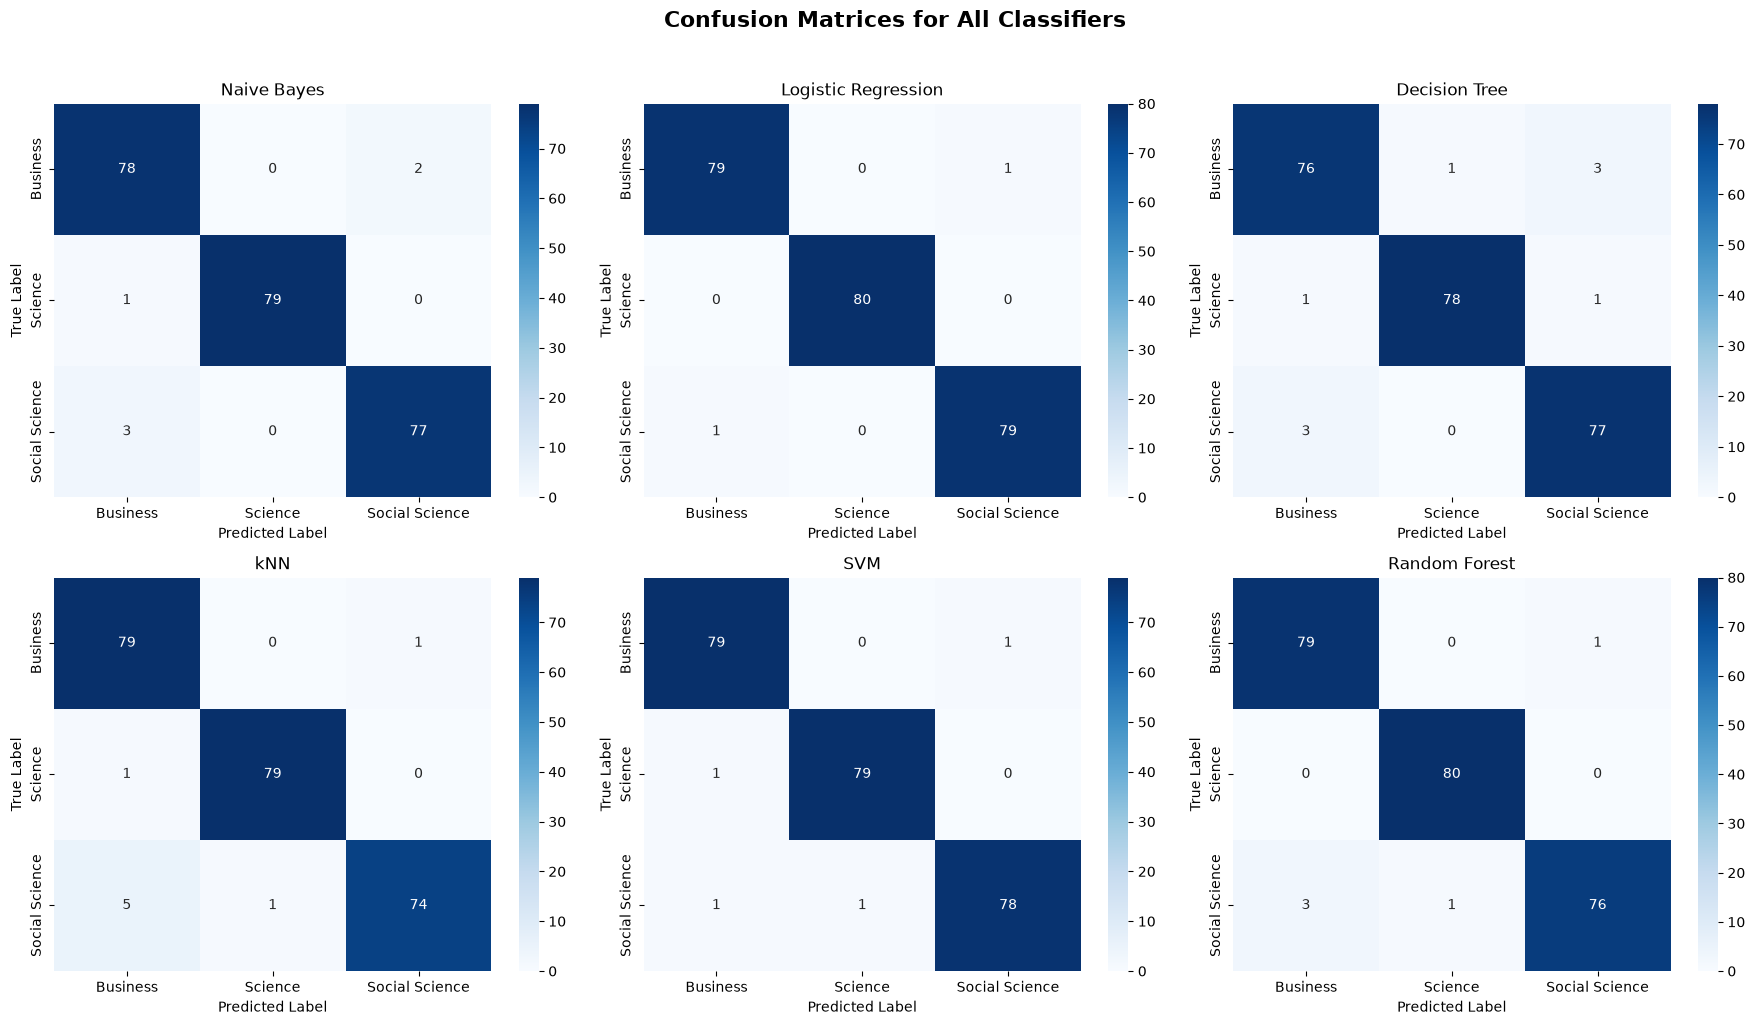

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

fig.suptitle('Confusion Matrices for All Classifiers', fontsize=16, fontweight='bold', y=1.02)

for idx, (name, y_pred) in enumerate(predictions_dict.items()):
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=target_names, yticklabels=target_names)
    
    axes[idx].set_title(f'{name}')
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('True Label')

plt.tight_layout()
plt.show()

### Model Accuracy Comparison

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11756\4110608831.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


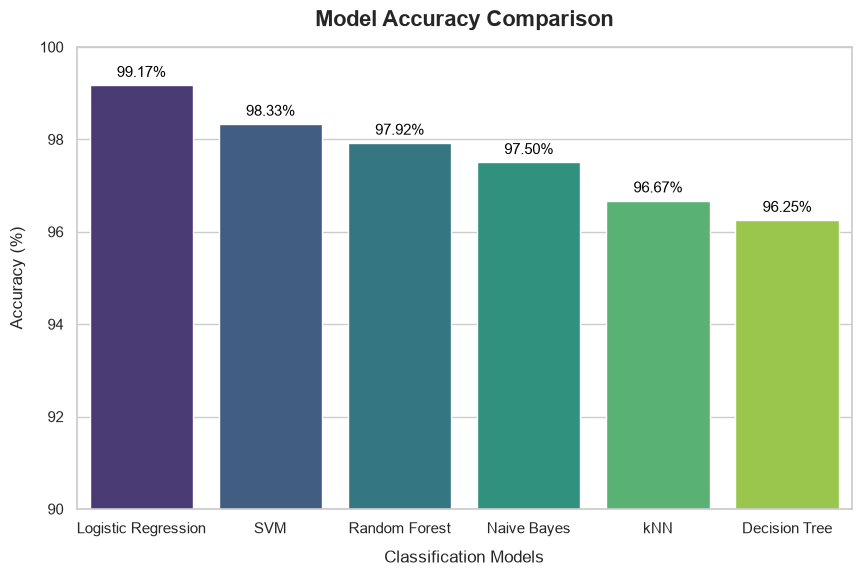

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Make copy of existing performance matrix dataframe
plot_df = df_results.copy()

# Convert the 0.00 to 1.00 scale into percentages (0 to 100) for graph
if plot_df['Accuracy'].max() <= 1.0:
    plot_df['Accuracy'] = plot_df['Accuracy'] * 100

# plot style
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Create bar chart directly from the dataframe columns
ax = sns.barplot(
    data=plot_df, 
    x='Model', 
    y='Accuracy', 
    palette="viridis"
)

# titles and labels
plt.title("Model Accuracy Comparison", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Classification Models", fontsize=12, labelpad=10)
plt.ylabel("Accuracy (%)", fontsize=12, labelpad=10)
plt.ylim(90, 100) # Zoomed in 

# Automatically annotate each bar with its exact percentage
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='baseline', 
                fontsize=11, color='black', xytext=(0, 6), 
                textcoords='offset points')

# Save the graph for GitHub and display it in the notebook
plt.savefig("accuracy_comparison.png", dpi=300)
plt.show()

## Interactive Demo

In [20]:
import ipywidgets as widgets
from IPython.display import display, HTML

# We use Logistic Regression because it supports predict_proba()
best_model = lr_model 

# 1. Create UI Elements
title = widgets.HTML("<h3>Interactive Abstract Classifier Demo (with Confidence Scores)</h3>")
text_input = widgets.Textarea(
    value='',
    placeholder='Paste a research abstract here...',
    description='Abstract:',
    layout=widgets.Layout(width='80%', height='150px')
)
predict_button = widgets.Button(
    description='Predict Category',
    button_style='success',
    tooltip='Click to predict the discipline'
)
output_area = widgets.Output()

# 2. Define the prediction pipeline
def on_predict_clicked(b):
    with output_area:
        output_area.clear_output()
        raw_text = text_input.value
        
        if len(raw_text.strip()) < 15:
            print("Please enter a longer abstract.")
            return
            
        print("Processing text...")
        
        # Step 1: Clean the text using NLP function
        clean_text = preprocess_abstract(raw_text)
        
        # Step 2: Convert text to math using TF-IDF vectorizer
        vec_text = tfidf_vectorizer.transform([clean_text])
        
        # Step 3: Get final prediction AND probability percentages
        pred_idx = best_model.predict(vec_text)[0]
        pred_label = label_mapping[pred_idx]
        probabilities = best_model.predict_proba(vec_text)[0]
        
        # Step 4: Print the results cleanly
        print("="*50)
        print(f"PREDICTED DISCIPLINE: {pred_label.upper()}")
        print("="*50)
        
        print("\nModel Confidence Breakdown:")
        
        # Match probabilities to their labels and sort from highest to lowest
        prob_dict = {label_mapping[i]: prob for i, prob in enumerate(probabilities)}
        sorted_probs = sorted(prob_dict.items(), key=lambda item: item[1], reverse=True)
        
        for label, prob in sorted_probs:
            # The :<15 formats the text to align perfectly in a column
            print(f"- {label:<15}: {prob * 100:.2f}%")
        print("="*50)

# 3. Link button and display UI
predict_button.on_click(on_predict_clicked)
display(title, text_input, predict_button, output_area)

HTML(value='<h3>Interactive Abstract Classifier Demo (with Confidence Scores)</h3>')

Textarea(value='', description='Abstract:', layout=Layout(height='150px', width='80%'), placeholder='Paste a r…

Button(button_style='success', description='Predict Category', style=ButtonStyle(), tooltip='Click to predict …

Output()